In [31]:
import pandas as pd
import numpy as np

train_data = pd.read_csv("train.csv")
test_data = pd.read_csv("test.csv")

def generate_data(training, testing, store, product):
    train_data = training[(training['store'] == store) & (training['product'] == product)]
    test_data = testing[(testing['store'] == store) & (testing['product'] == product)]
    return train_data[['Date', 'number_sold']], test_data[['Date', 'number_sold']]


full_data = pd.concat(generate_data(train_data, test_data, 3, 3))

full_data.head()

# feature generation

full_data['lag_1'] = full_data['number_sold'].shift(1) # 1 day lag
full_data['lag_7'] = full_data['number_sold'].shift(7) # 1 week lag
full_data['lag_30'] = full_data['number_sold'].shift(30) # 1 month lag
full_data['lag_90'] = full_data['number_sold'].shift(90) # 1 quarter lag

# rolling features 

def create_rolling_features(data, target_col, windows):
    result = data.copy()
    for window in windows:
        result[f'rolling_mean_{window}'] = result[target_col].shift(1).rolling(window).mean()
        result[f'rolling_std_{window}'] = result[target_col].shift(1).rolling(window).std()
        result[f'rolling_min_{window}'] = result[target_col].shift(1).rolling(window).min()
        result[f'rolling_max_{window}'] = result[target_col].shift(1).rolling(window).max()
        result[f'rolling_median_{window}'] = result[target_col].shift(1).rolling(window).median()
    return result

windows = [1, 7, 30, 90]
full_data = create_rolling_features(full_data, 'number_sold', windows)

train_data = full_data[full_data['Date'] < '2019-01-01']
test_data = full_data[full_data['Date'] >= '2019-01-01']


X_train = train_data.drop(columns=['Date', 'number_sold'], errors='ignore')
y_train = train_data[['number_sold']]

X_test = test_data.drop(columns=['Date', 'number_sold'], errors='ignore')
y_test = test_data[['number_sold']]

In [32]:
import lightgbm as lgb

param = {
    'objective' : 'regression',
    'metric' : ['mape', 'rmse'],
    'learning_rate': 0.07
}

train_data = lgb.Dataset(X_train, y_train)

lightgb = lgb.train(train_set=train_data, params=param)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002554 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2893
[LightGBM] [Info] Number of data points in the train set: 3287, number of used features: 23
[LightGBM] [Info] Start training from score 324.375418


In [33]:
from sklearn.metrics import mean_absolute_percentage_error, mean_squared_error

y_pred = lightgb.predict(X_test)

mae = mean_absolute_percentage_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f'MAPE: {mae}')
print(f'RMSE: {rmse}')

MAPE: 0.02629723378243382
RMSE: 11.18523378078741


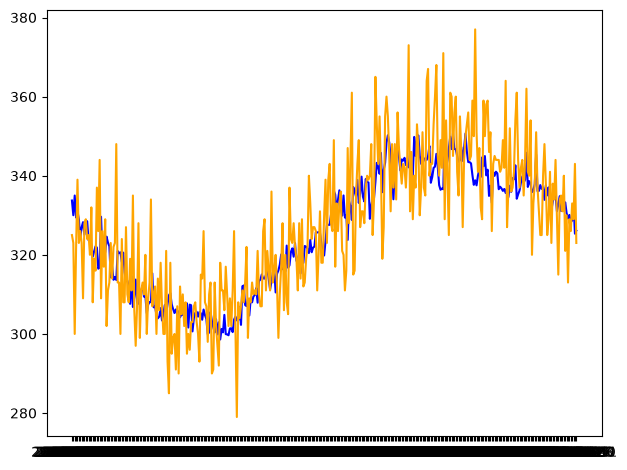

In [34]:
import matplotlib.pyplot as plt

plt.plot(test_data['Date'], y_pred, color='blue')
plt.plot(test_data['Date'], y_test, color='orange')
plt.tight_layout()